### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [27]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
)
from data_processing.utils import (
    load_scaler_params,
    load_checkpoint,
    load_torch_model,
    QuantileDistribution,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
import torch

In [2]:
# TODO
# DONE load evaluation input
# fix column names
# DONE calculate capacity factor
# DONE load model from checkpoint
# DONE (select bidding zone)
# DONE evaluate model for (all) bidding zone
# multiply with available capacity to get absolute generated power
# DONE save median, q025 and q975 in a CSV
# DONE verify format with verify_example.py
# check how good forecast was afterwards (in competition one day later)

In [3]:
forecast = load_weather_forecast_parquet("../data/met_forecast.parquet")

In [4]:
forecast

,sid,time_ref,time,lt,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,...,g10m_05,g10m_06,g10m_07,g10m_08,g10m_09,g10m_10,g10m_11,g10m_12,g10m_13,g10m_14
0,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 13:00:00+01:00,0,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,...,6.918935,8.110546,5.988888,6.934274,5.235212,5.507061,7.193576,6.753938,4.841811,4.875890
1,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 14:00:00+01:00,1,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,...,9.914339,9.184751,6.999992,7.892150,7.214608,8.252510,9.535547,8.717684,8.152432,6.240438
2,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 15:00:00+01:00,2,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,...,10.031385,8.624619,7.984353,8.264300,7.205638,9.052546,9.531441,8.367238,7.840395,7.153080
3,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 16:00:00+01:00,3,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,...,8.185250,8.821701,7.481009,8.172009,6.255360,7.345034,8.303812,6.735660,7.600200,7.189164
4,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 17:00:00+01:00,4,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,...,7.551644,9.709259,8.365305,8.703517,6.151643,10.116440,7.346225,9.079601,9.048587,6.937930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6874207,Hamnefjell,2025-03-15 10:00:00+01:00,2025-03-18 02:00:00+01:00,64,6.872266,7.164222,6.316023,5.589070,6.980499,4.612734,...,7.563049,8.551785,9.509587,9.794330,8.066090,8.411860,10.138005,2.795730,9.581801,7.873007
6874208,Hamnefjell,2025-03-16 10:00:00+01:00,2025-03-19 02:00:00+01:00,64,16.470940,16.099072,7.887674,14.270714,4.360876,10.369994,...,14.324461,30.275700,8.210348,18.635717,10.935499,18.720608,26.935497,6.617165,21.847015,31.888178
6874209,Hamnefjell,2025-03-22 10:00:00+01:00,2025-03-25 02:00:00+01:00,64,10.446624,9.178246,12.801767,9.458190,9.951641,8.660180,...,13.481665,18.230787,13.330455,16.758130,10.482368,10.948782,14.067688,15.863382,13.946945,12.476421
6874210,Hamnefjell,2025-03-23 10:00:00+01:00,2025-03-26 02:00:00+01:00,64,18.683716,16.797531,16.638610,16.367867,17.087458,13.853215,...,19.608253,25.046673,13.443735,19.931894,24.276434,25.254436,17.580925,24.548616,27.329407,19.575188


In [47]:
bid_zone = "ELSPOT NO1"
evaluation_dates = [
    "2025-09-22",
    "2025-09-23",
    "2025-09-24",
    "2025-09-25",
    "2025-09-26",
    "2025-09-29",
    "2025-09-30",
    "2025-10-01",
    # "2025-10-02",
    # "2025-10-03",
]

In [48]:
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]

### Load params and evaluation data


In [49]:
# Load scaler params (same for all models in this bid zone)
scaler_data = load_scaler_params(bid_zone=bid_zone, dir_path="../checkpoints")

Loaded scaler parameters for ELSPOT NO1
  Saved at: 2025-12-01 09:55:42
  Split time: 2025-01-01 00:00:00+01:00


In [50]:
# Load evaluation data for multiple dates (using the evaluation_dates list)
eval_data = load_evaluation_data(
    dates=evaluation_dates,
    scaler_params=scaler_data["scaler_params"],
    site_scaler_params=scaler_data["site_scaler_params"],
    bid_zone=bid_zone,
    dataset="nowcast",
    ensemble_member=0,
)

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Loading evaluation data for 8 dates in zone ELSPOT NO1...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO1
Filtered to target day: 2025-09-22
Loading evaluation data for 2025-09-23 in zone ELSPOT NO1
Filtered to target day: 2025-09-23
Loading evaluation data for 2025-09-24 in zone ELSPOT NO1
Filtered to target day: 2025-09-24
Loading evaluation data for 2025-09-25 in zone ELSPOT NO1
Filtered to target day: 2025-09-25
Loading evaluation data for 2025-09-26 in zone ELSPOT NO1
Filtered to target day: 2025-09-26
Loading evaluation data for 2025-09-29 in zone ELSPOT NO1
Filtered to target day: 2025-09-29
Loading evaluation data for 2025-09-30 in zone ELSPOT NO1
Filtered to target day: 2025-09-30
Loading evaluation data for 2025-10-01 in zone ELSPOT NO1
Filtered to target day: 2025-10-01


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Evaluation data shape: X=(192, 6, 6), Y_gen=(192,)


In [9]:
# Load trained model checkpoint, bidding zone specific!
checkpoint = load_checkpoint(file_name="model_mw_gamma_2025-11-13_10-56-50_gen")

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-11-13_10-56-50_gen.pkl


### Run inference


In [10]:
_, rng_key_predict = random.split(checkpoint["rng_key"])

predictive = Predictive(model_mw_gamma, checkpoint["samples"])(
    rng_key_predict, eval_data["X_eval"]
)

preds = predictive["Y"]
mu = predictive["mu"]
alpha = predictive["alpha"]

median = np.percentile(preds, 50, axis=0)
q025 = np.percentile(preds, 2.5, axis=0)
q975 = np.percentile(preds, 97.5, axis=0)
hdi = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

### Save predictions as CSV


In [51]:
forecast = pd.DataFrame(
    index=eval_data["index"],
    columns=bid_zones,
    data=0,
)
forecast_extended = [
    pd.DataFrame(
        index=eval_data["index"],
        columns=["median", "hdi_lower", "hdi_upper"],
        data=0,
    )
    for _ in range(len(bid_zones))
]

### Evaluate BNN


In [52]:
model_mapping = {
    "model_cf_beta": model_cf_beta,
    "model_mw_gamma": model_mw_gamma,
    "model_cf_logitnormal": model_cf_logitnormal,
}

for i, bz in enumerate(bid_zones):

    # Load bid zone specific trained model checkpoint
    file_name = "model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1"  # "model_mw_gamma_2025-11-13_10-56-50_gen"
    model_name = re.match(r"^(.*?)_\d{4}-\d{2}-\d{2}", file_name).group(1)

    checkpoint = load_checkpoint(file_name=file_name)  # TODO make it bid zone specific

    # Run inference
    _, rng_key_predict = random.split(checkpoint["rng_key"])

    predictive = Predictive(model_mapping[model_name], checkpoint["samples"])(
        rng_key_predict, eval_data["X_eval"]
    )

    preds = predictive["Y"]
    if "cf" in checkpoint["model_name"]:
        preds *= eval_data["Y_eval_aval"]

    median = np.percentile(preds, 50, axis=0)
    hdis = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)
    hdi_lower, hdi_upper = hdis[:, 0], hdis[:, 1]

    forecast[bz] = median
    forecast_extended[i][["median", "hdi_lower", "hdi_upper"]] = np.column_stack(
        [median, hdi_lower, hdi_upper]
    )

    break  # TODO no checkpoints for other bid zones so far

Loading specified checkpoint: ../checkpoints/model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1.pkl


### Evaluate deterministic NN


In [20]:
for i, bz in enumerate(bid_zones):

    loaded_model, checkpoint_data = load_torch_model(
        file_name="WindPowerQuantile_2025-12-01_09-59-33_ELSPOT_NO1"  # "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"  #
    )

    loaded_model.eval()
    with torch.no_grad():

        if "Quantile" in checkpoint_data["model_name"]:
            y_sum_pred = loaded_model(torch.tensor(eval_data["X_eval"]))
            Y_pred = y_sum_pred.numpy()

            taus = np.linspace(0, 1, 51)
            dist = QuantileDistribution(taus, np.mean(Y_pred, axis=0))
            hdis = np.array(
                [
                    QuantileDistribution(taus, Y_pred[i]).hdi(
                        cred_mass=0.95, n_samples=5000
                    )
                    for i in range(eval_data["Y_eval_gen"].shape[0])
                ]
            )

            medians = np.array(
                [
                    QuantileDistribution(taus, Y_pred[i]).icdf(0.5)
                    for i in range(eval_data["Y_eval_gen"].shape[0])
                ]
            )

            forecast_extended[i][["median", "hdi_lower", "hdi_upper"]] = (
                np.column_stack([medians, hdis[:, 0], hdis[:, 1]])
            )

        else:  # TODO catch more models here
            _, y_sum_pred = loaded_model(torch.tensor(eval_data["X_eval"]))
            y_sum_pred = y_sum_pred.numpy() * eval_data["Y_eval_aval"]  # CF
            medians = np.percentile(y_sum_pred, 50, axis=0)

    forecast[bz] = medians

    break  # TODO no checkpoints for other bid zones so far

WindPowerQuantile
Loaded model: WindPowerQuantile_2025-12-01_09-59-33_ELSPOT_NO1.pt
  Bid zone: ELSPOT NO1
  Model class: WindPowerQuantile


In [ ]:
# Save predictions to CSV
data_folder = f"../data/evaluation/eval_period"
file_path = f"{data_folder}/forecast.csv"
if not os.path.exists(data_folder):
    os.makedirs(data_folder)
forecast.to_csv(file_path)

In [ ]:
forecast

In [ ]:
# # Validate format
# df = validate_forecast(file_path)

### Metrics


In [53]:
i = 0  # [0,1,2,3], choose which bid zone should be plotted
bid_zone = f"ELSPOT_NO{i+1}"

In [54]:
rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))
print("Test RMSE (gen prediction):", rmse)

Test RMSE (gen prediction): 53.309246


In [44]:
inside = (eval_data["Y_eval_gen"] >= forecast_extended[i]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecast_extended[i]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_data["Y_eval_gen"] <= forecast_extended[i]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")


Empirical coverage (0.025–0.975): 0.849
Below median (should be ~0.5): 0.359


### Plot prediction


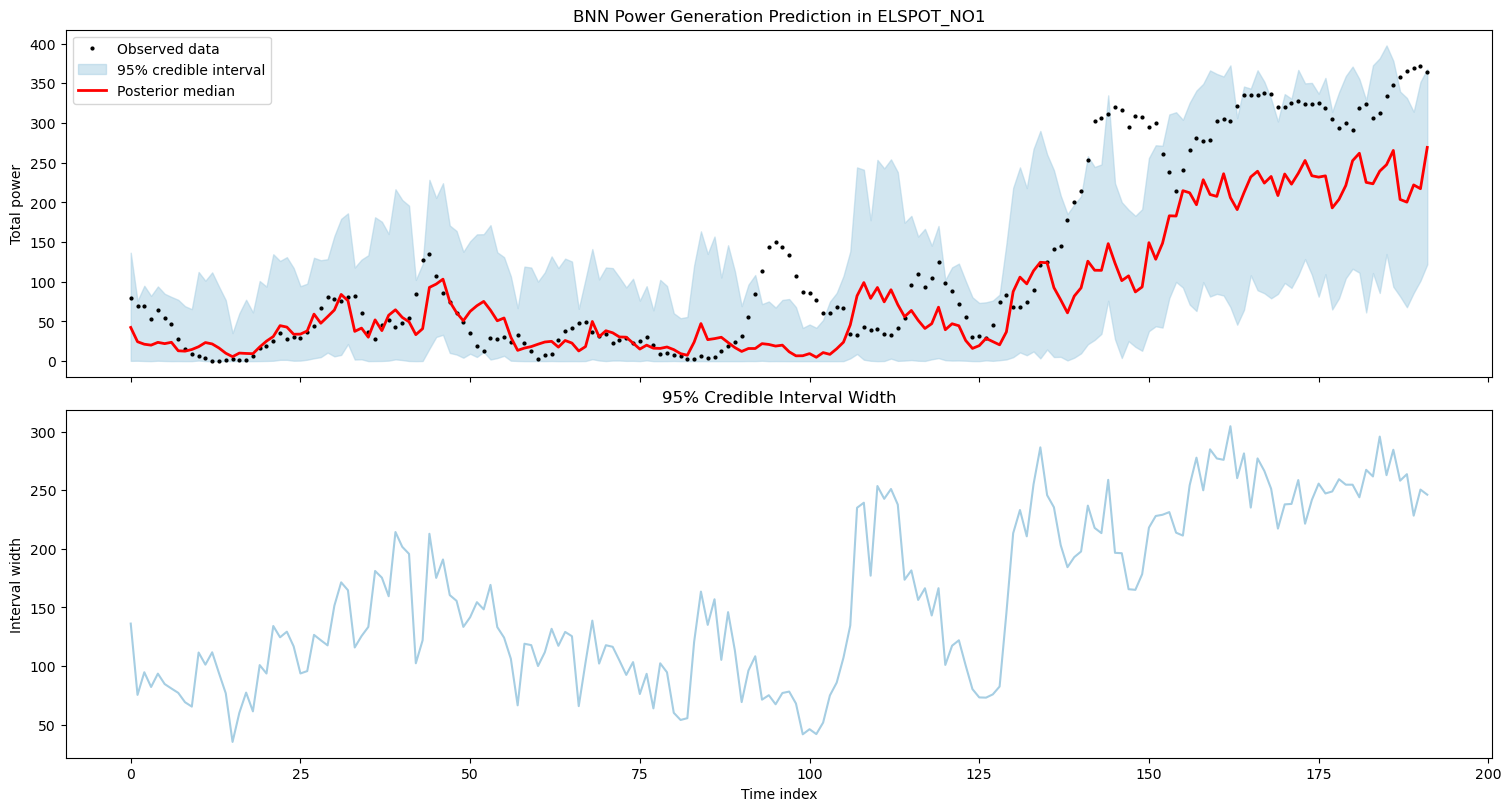

In [45]:
fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    np.arange(24 * len(evaluation_dates)),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    ylabel="Total power",
    title=f"BNN Power Generation Prediction in {bid_zone}",
)
ax.legend()


# Compute interval width
width = (
    forecast_extended[i]["hdi_upper"].values - forecast_extended[i]["hdi_lower"].values
)
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

plt.show()

In [ ]:
# # First, load nowcast data (or load existing scaler params)
# nowcast_data = load_and_preprocess_data(bid_zone="ELSPOT NO1")

In [53]:
import importlib
import data_processing.load as load_module

importlib.reload(load_module)
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
)

In [54]:
# # Now load forecast data using the SAME scaler parameters

forecast_data = load_and_preprocess_forecast_data(
    scaler_params=None,
    site_scaler_params=None,
    bid_zone="ELSPOT NO1",
    ensemble_member=0,  # Use member 0
    data_path="../data",
)

Loading forecast data for ELSPOT NO1, ensemble member 0...
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79
Selected ensemble member 0
  Features: ['wind_speed_10m', 'wind_direction_10m', 'air_temperature_2m', 'relative_humidity_2m', 'air_pressure_at_sea_level']
Before 2-day ahead filtering: 6874212 rows
After 2-day ahead filtering: 2592073 rows
Lead time range: 34.0h to 61.0h
                                  windpark                  time_ref  \
2020-02-17 00:00:00+01:00     Engerfjellet 2020-02-15 13:00:00+01:00   
2020-02-17 00:00:00+01:00  Marker Vindpark 2020-02-15 13:00:00+01:00   
2020-02-17 00:00:00+01:00       Kjølberget 2020-02-15 13:00:00+01:00   
2020-02-17 00:00:00+01:00       Songkjølen 2020-02-15 13:00:00+01:00   
2020-02-17 00:00:00+01:00     Hån Vindpark 2020-02-15 13:00:00+01:00   

                           lead_time_hours  wind_speed_10m  \
2020-02-17 00:

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

No feature scaler parameter provided, computing new ones.
Preprocessing done. X_train shape: (18141, 6, 6)
Preprocessing done. X_test shape: (1896, 6, 6)


In [50]:
forecast_data.keys()

dict_keys(['X_train', 'X_test', 'Y_train_cf', 'Y_train_aval', 'Y_train_gen', 'Y_test_cf', 'Y_test_aval', 'Y_test_gen', 'sites_meta', 'feature_cols', 'scaler_params', 'site_scaler_params'])